# Statistics 2: Probability and simulation

*Learning path: probability and statistics, part 2 of 8.* [Index](README.md) · Previous: [Describing data](01-describing-data.ipynb) · Next: [Discrete distributions](03-discrete-distributions.ipynb)

In 1654 a gambler, the Chevalier de Méré, asked Blaise Pascal why he kept losing a bet he thought he should win:
getting a double six in 24 throws of two dice. Pascal and Pierre de Fermat worked it out in letters, and probability
theory was born. Today the same questions (how likely, and how surprising) underlie medical tests, insurance, and
every claim that a result is "statistically significant". This lesson builds probability from counting, checks every
answer by simulating it thousands of times, and ends with the rule that confuses even doctors: Bayes' rule.

**Who this is for.** You have done [lesson 1](01-describing-data.ipynb). Fractions and powers are all the algebra
needed.

**What you will be able to do afterwards:**

1. compute probabilities by counting equally likely outcomes, and with the complement and product rules;
2. simulate a random experiment many times and compare the frequencies with the exact answer;
3. solve the birthday problem and de Méré's problem;
4. use conditional probability and Bayes' rule to interpret a medical test.

Plan about an hour.

## 1. Counting equally likely outcomes

When all outcomes are equally likely, $P(A) = \dfrac{\text{number of outcomes in } A}{\text{number of outcomes}}$.
Two dice have $6 \times 6 = 36$ outcomes. A sum of 7 happens in 6 ways ($1+6, 2+5, \ldots, 6+1$), so
$P(\text{sum} = 7) = 6/36 = 1/6$; a sum of 2 only one way. All eleven sums:

1

> `sum`: Sum or product of f for k = a, a+1, ..., b; sum(A) adds the entries of a matrix.

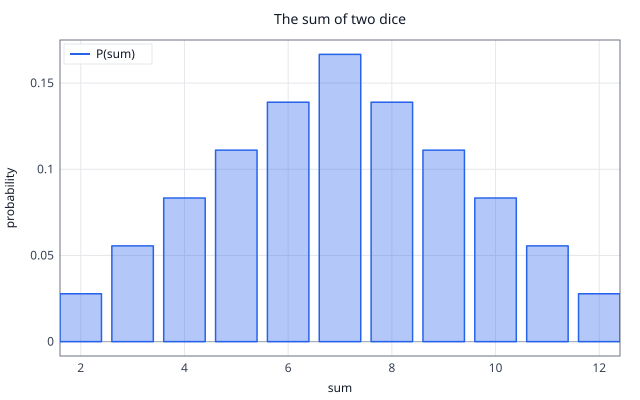

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [1]:
sums = [2 3 4 5 6 7 8 9 10 11 12];
probs = [1 2 3 4 5 6 5 4 3 2 1]/36;
sum(probs)
p = bar(sums, probs);
labels(title(legend(p, "P(sum)"), "The sum of two dice"), "sum", "probability")

Now roll them 6000 times. `randint(1, 6, 6000)` gives 6000 throws of one die; adding two such lists adds them throw by
throw, and `tally` counts:

In [2]:
seed(1);
a = randint(1, 6, 6000);
b = randint(1, 6, 6000);
tally(a + b)

[  2,   3,   4,   5,   6,    7,   8,   9,  10,  11,  12;
 163, 329, 491, 675, 844, 1040, 785, 690, 504, 303, 176]

> tally: the first row lists the distinct values, the second how often each occurs.

A 7 came up 1040 times; the exact probability predicts $6000/6 = 1000$. The **frequencies approach the
probabilities** as the number of trials grows (the law of large numbers, [lesson 5](05-sampling-and-clt.ipynb)), but
never match exactly: a difference of 40 in 6000 is ordinary chance.

**Try this.** What is $P(\text{sum} \ge 10)$? Count it from the list, then estimate it from the simulation with
`sum(a + b >= 10)/6000`.

## 2. Complements and products: de Méré's problem

Two rules do most of the work:

* **complement**: $P(\text{not } A) = 1 - P(A)$, useful for "at least one";
* **product**: for independent events, $P(A \text{ and } B) = P(A)\,P(B)$.

De Méré's first bet: at least one six in 4 throws of one die. No six in one throw has probability $5/6$; in four
independent throws $(5/6)^4$; so

In [3]:
simplify(1 - (5/6)^4)
eval(1 - (5/6)^4)

671/1296

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

0.5177469135802469

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

A bit better than even, 0.518. His second bet: at least one double six in 24 throws of two dice. A double six has
probability $1/36$, so:

In [4]:
eval(1 - (35/36)^24)

0.49140387613090325

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.491: slightly worse than even, which is why he lost money over many games. Simulate the first bet: a $4 \times 10000$
matrix of throws, one column per game. `A > 5.5` marks the sixes with 1, multiplying by a row of ones counts the sixes
in each column, and the games with at least one six are those with a count above 0:

In [5]:
A = randint(1, 6, 4, 10000);
sixes = ones(1, 4)*(A > 5.5);
simplify(sum(sixes > 0.5)/10000)

0.5126

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

$2563/5000 = 0.513$ of the simulated games had a six, close to the exact 0.518.

**Try this.** What is the probability of at least one head in 10 tosses of a fair coin? Do it with the complement.

## 3. The birthday problem

In a room of 23 people, what is the probability that two share a birthday? Use the complement: all birthdays
different. The first person can have any of 365 days, the second any of the other 364, and so on:

$$P(\text{all different}) = \frac{365}{365}\cdot\frac{364}{365}\cdots\frac{343}{365} = \prod_{k=0}^{22}\frac{365 - k}{365}.$$

In [6]:
eval(1 - prod((365 - k)/365, k, 0, 22))

0.5072972343239854

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Just over a half, with only 23 people. The intuition fails because there are $\binom{23}{2} = 253$ pairs, and each
pair is a chance for a match. Each pair matches with probability $1/365$, and treating the pairs as if they were
independent gives a good approximation for $n$ people:

$$P(\text{some shared birthday}) \approx 1 - \left(\frac{364}{365}\right)^{n(n-1)/2} \approx 1 - e^{-n(n-1)/730}.$$

For 23 people it gives 0.500 against the exact 0.507. As a function of the number of people:

0.5000017521827107

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

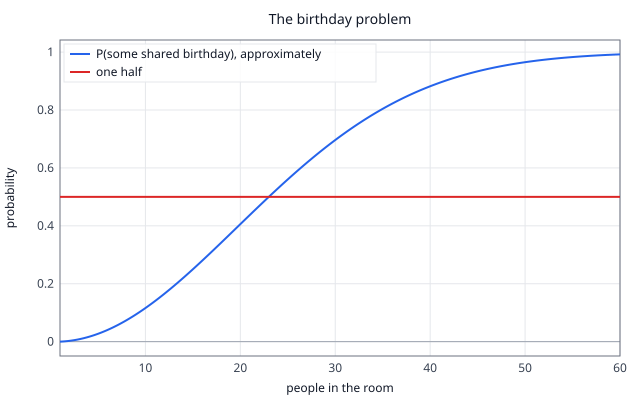

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
eval(1 - exp(-23*22/730))
p = plot(1 - exp(-n*(n - 1)/730), n, 1, 60);
p = show(p, plot(1/2, n, 1, 60));
p = legend(p, "P(some shared birthday), approximately", "one half");
labels(title(p, "The birthday problem"), "people in the room", "probability")

(Real birthdays are not quite uniform over the year, which makes matches slightly more likely still.)

**Try this.** How many people are needed for a 99% chance of a shared birthday? Read it off the graph, then check
with `eval(1 - prod((365 - k)/365, k, 0, 56))`.

## 4. Conditional probability and Bayes' rule

A disease affects 1% of people. A test detects it in 95% of sick people (**sensitivity**) and gives a false alarm in
5% of healthy people. You test positive. How likely is it that you are sick?

Picture 10,000 people: 100 are sick and 95 of them test positive; 9900 are healthy and 5% of them, 495, test positive
anyway. Of the $95 + 495 = 590$ positives, only 95 are sick:

In [8]:
simplify(95/(95 + 495))
eval(95/(95 + 495))

19/118

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

0.16101694915254236

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Only 16%. This is **Bayes' rule**:

$$P(\text{sick} \mid +) = \frac{P(+ \mid \text{sick})\,P(\text{sick})}{P(+ \mid \text{sick})\,P(\text{sick}) + P(+ \mid \text{healthy})\,P(\text{healthy})} = \frac{0.95 \cdot 0.01}{0.95 \cdot 0.01 + 0.05 \cdot 0.99}.$$

The **conditional probability** $P(A \mid B)$, "A given B", restricts attention to the cases where $B$ happened. When
the disease is rare, false alarms from the large healthy group outnumber the true positives. In studies, many doctors
estimate this probability at 80% or more.

How the answer depends on how common the disease is:

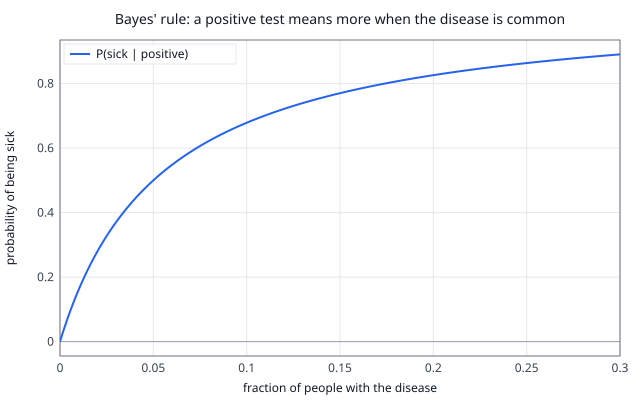

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [9]:
p = plot(0.95*q/(0.95*q + 0.05*(1 - q)), q, 0, 0.3);
p = legend(p, "P(sick | positive)");
labels(title(p, "Bayes' rule: a positive test means more when the disease is common"), "fraction of people with the disease", "probability of being sick")

**Try this.** A second, independent test is also positive. Use 16% (that is, $95/590$) as the new starting fraction
and apply Bayes' rule again. What is the probability now?

## Summary

* Equally likely outcomes: $P(A) = $ favourable / total. Complement: $P(\text{not } A) = 1 - P(A)$. Independent
  events multiply.
* Simulation estimates probabilities by frequencies; they approach the exact value as the trials grow.
* "At least one" problems (de Méré, birthdays) are easiest through the complement.
* Conditional probability restricts to the cases where the condition holds; Bayes' rule turns $P(+ \mid \text{sick})$
  into $P(\text{sick} \mid +)$, and the base rate matters.

Next: [discrete distributions](03-discrete-distributions.ipynb), where counting turns into formulas.

## Exercises

1. **Three coins.** List the 8 outcomes of three coin tosses and find $P(\text{exactly two heads})$.
2. **Cards.** What is the probability that a 5-card hand has no ace? (Use `binomial(48, 5)/binomial(52, 5)`.)
3. **Simulated birthdays.** Simulate 23 birthdays with `randint(1, 365, 23)` and check for a match with `tally`
   (does any count exceed 1?). Repeat a few times with different seeds.
4. **Monty Hall.** A car is behind one of three doors; you pick one, the host opens another door with a goat, and you
   may switch. Simulate with `car = randint(1, 3, 10000)` and `pick = randint(1, 3, 10000)`: staying wins when
   `abs(car - pick) < 1/2`. What fraction wins by staying, and so by switching?
5. **Bayes.** 30% of emails are spam. The word "prize" appears in 20% of spam and 1% of other emails. Given "prize",
   what is the probability that an email is spam?

## Hints and answers

* **Section 1, Try this.** $(3 + 2 + 1)/36 = 1/6$; the simulation gives a number near 0.167.
* **Section 2, Try this.** $1 - (1/2)^{10} = 1023/1024$.
* **Section 3, Try this.** 57 people: the probability is about 0.990.
* **Section 4, Try this.** With starting fraction $95/590$: $\frac{0.95 \cdot 0.161}{0.95 \cdot 0.161 + 0.05 \cdot
  0.839} \approx 0.78$.
* **Exercise 1.** HHT, HTH, THH: $3/8$.
* **Exercise 2.** $\binom{48}{5}/\binom{52}{5} \approx 0.659$.
* **Exercise 3.** About half of the seeds give a match.
* **Exercise 4.** Staying wins about 1/3 of the time, so switching wins about 2/3.
* **Exercise 5.** $\frac{0.2 \cdot 0.3}{0.2 \cdot 0.3 + 0.01 \cdot 0.7} = 60/67 \approx 0.90$.

## Sources

1. B. Pascal and P. de Fermat, letters of 1654, translated in D. E. Smith, *A Source Book in Mathematics*,
   McGraw-Hill (1929), 546–565.
2. W. Feller, *An Introduction to Probability Theory and Its Applications*, vol. 1, 3rd ed., Wiley (1968), chapters 1,
   2 and 5.
3. G. Gigerenzer and U. Hoffrage, "How to improve Bayesian reasoning without instruction: frequency formats",
   *Psychological Review* 102 (1995) 684–704.
4. T. Bayes, "An essay towards solving a problem in the doctrine of chances", *Philosophical Transactions of the Royal
   Society* 53 (1763) 370–418.